# Lab 8 (Week 2 — Lab 3): Classification Models

Welcome to Lab 8! In this lab you will build classification models that predict a category instead of a number. You'll practice Logistic Regression, K-Nearest Neighbors, and Decision Trees using the Iris dataset.

**For detailed theory on how each algorithm works, see the Lab 8 PDF and Learning Resources.**

This notebook focuses on the practical, hands-on workflow.

**Instructions:**
- Write your code between the `### YOUR CODE HERE ###` and `### END ###` markers.
- Run each cell with **Shift + Enter**.
- Compare your output with the **Expected Output** shown below each exercise where provided.

## Getting the Dataset

This lab uses the Iris dataset, which is built directly into scikit-learn — no download or upload needed.

In [1]:
from sklearn.datasets import load_iris
import pandas as pd
import numpy as np

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target_names[iris.target]

print(df.shape)
df.head()

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
from sklearn.model_selection import train_test_split

X = df[iris.feature_names]
y = iris.target   # numeric labels: 0, 1, 2

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])

Training set size: 120
Test set size: 30


## Example 1: Logistic Regression

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

log_model = LogisticRegression(max_iter=200)
log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))

Logistic Regression Accuracy: 1.0


## Example 2: K-Nearest Neighbors (KNN)

In [4]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

KNN Accuracy: 1.0


## Example 3: Decision Tree

In [5]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_tree))

Decision Tree Accuracy: 1.0


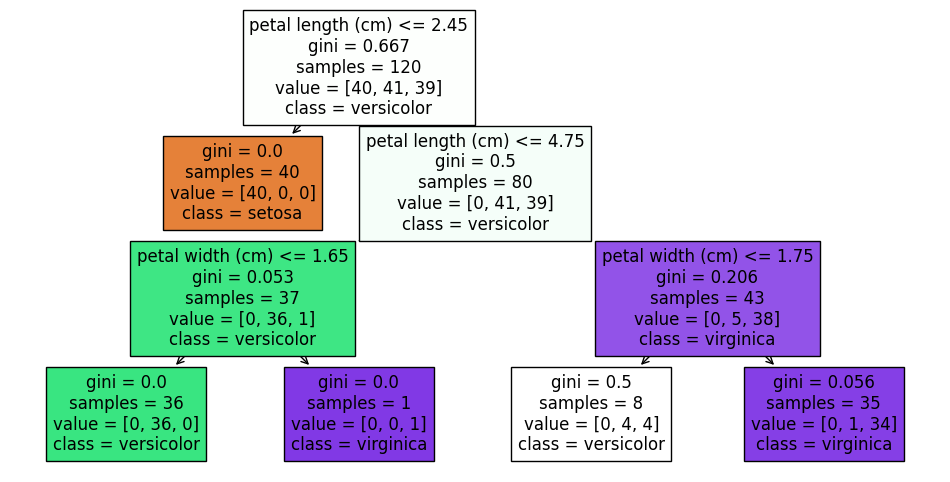

In [6]:
plt.figure(figsize=(12, 6))
plot_tree(tree_model, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()

## Practice Exercise 1: KNN with a Different k

**Exercise:** Train a KNN model with `n_neighbors=3` instead of 5. Compare its accuracy to the k=5 version from Example 2.

In [7]:
knn_model_3 = None
accuracy_knn3 = None

### YOUR CODE HERE ###
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
### END ###

print("KNN (k=3) Accuracy:", accuracy_knn3)

KNN Accuracy: 1.0
KNN (k=3) Accuracy: None


## Practice Exercise 2: Decision Tree Depth Comparison

**Exercise:** Train a Decision Tree with `max_depth=1` (a very shallow tree) and compare its accuracy to the `max_depth=3` version from Example 3. What do you notice?

In [8]:
### YOUR CODE HERE ###
tree_model_1 = DecisionTreeClassifier(max_depth=1, random_state=42)
tree_model_1.fit(X_train, y_train)

y_pred_tree_1 = tree_model_1.predict(X_test)

print("Depth=3 accuracy:", accuracy_score(y_test, y_pred_tree))
print("Depth=1 accuracy:", accuracy_score(y_test, y_pred_tree_1))
### END ###

Depth=3 accuracy: 1.0
Depth=1 accuracy: 0.6333333333333333


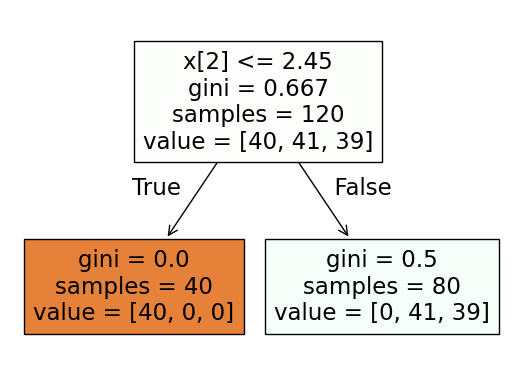

In [9]:
plot_tree(tree_model_1, filled=True)
plt.show()

_Write your observation about shallow vs. deeper trees here._
> **Observation:** The depth-1 tree scored **___** accuracy versus **___** for the depth-3 tree. A single split gives only two leaves, so the stump is too simple to separate all the classes, which is underfitting (high bias). Depth 3 can make more splits and fits the data much better while still generalizing. Going much deeper would eventually risk overfitting.

Fill in the blanks with your actual numbers.

## Practice Exercise 3: Predicting a New Sample

**Exercise:** Create a new, single flower measurement (choose any reasonable values for the 4 features) and use your trained Logistic Regression model to predict its species.

In [11]:
new_sample = None   # should be a 2D array/list with one row of 4 measurements
predicted_species = None

### YOUR CODE HERE ###
new_sample = [[6.0, 2.9, 4.5, 1.5]]   # sepal length, sepal width, petal length, petal width (cm)

pred = log_model.predict(new_sample)
predicted_species = iris.target_names[pred[0]]
### END ###

print("Predicted species:", predicted_species)

Predicted species: versicolor


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


## Lab Tasks

Complete the following in this notebook, below this cell.

1. **Train All Three Models**: Train Logistic Regression, KNN (k=5), and a Decision Tree (max_depth=3) on the Iris dataset, and print the accuracy of each.
2. **Model Comparison Table**: Create a small summary (a Pandas DataFrame or printed table) comparing the accuracy of all three models side by side.
3. **Hyperparameter Exploration**: Try at least 3 different values of `n_neighbors` for KNN (e.g., 1, 5, 10) and report which gives the best accuracy.
4. **Visualize the Tree**: Plot your Decision Tree model using `plot_tree()`, and in a markdown cell, describe in your own words what the first split (the root of the tree) is checking.
5. **Reflection**: In a markdown cell, write 3-4 sentences on which model performed best on this dataset, and one reason you think that might be the case.

In [12]:
# Task 1
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load and split
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define the three models
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree (max_depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42),
}

# Train each one and print its test accuracy
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"{name}: accuracy = {accuracy_score(y_test, y_pred):.3f}")

Logistic Regression: accuracy = 1.000
KNN (k=5): accuracy = 1.000
Decision Tree (max_depth=3): accuracy = 1.000


In [13]:
# Task 2
import pandas as pd

results = []
for name, model in models.items():
    acc = accuracy_score(y_test, model.predict(X_test))
    results.append({"Model": name, "Accuracy": round(acc, 3)})

comparison_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
print(comparison_df)

                         Model  Accuracy
0          Logistic Regression       1.0
1                    KNN (k=5)       1.0
2  Decision Tree (max_depth=3)       1.0


In [14]:
# Task 3
k_values = [1, 5, 10]
knn_results = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    knn_results.append({"n_neighbors": k, "Accuracy": round(acc, 3)})

knn_df = pd.DataFrame(knn_results)
print(knn_df)

best = knn_df.loc[knn_df["Accuracy"].idxmax()]
print(f"\nBest: n_neighbors={int(best['n_neighbors'])} with accuracy {best['Accuracy']}")

   n_neighbors  Accuracy
0            1       1.0
1            5       1.0
2           10       1.0

Best: n_neighbors=1 with accuracy 1.0


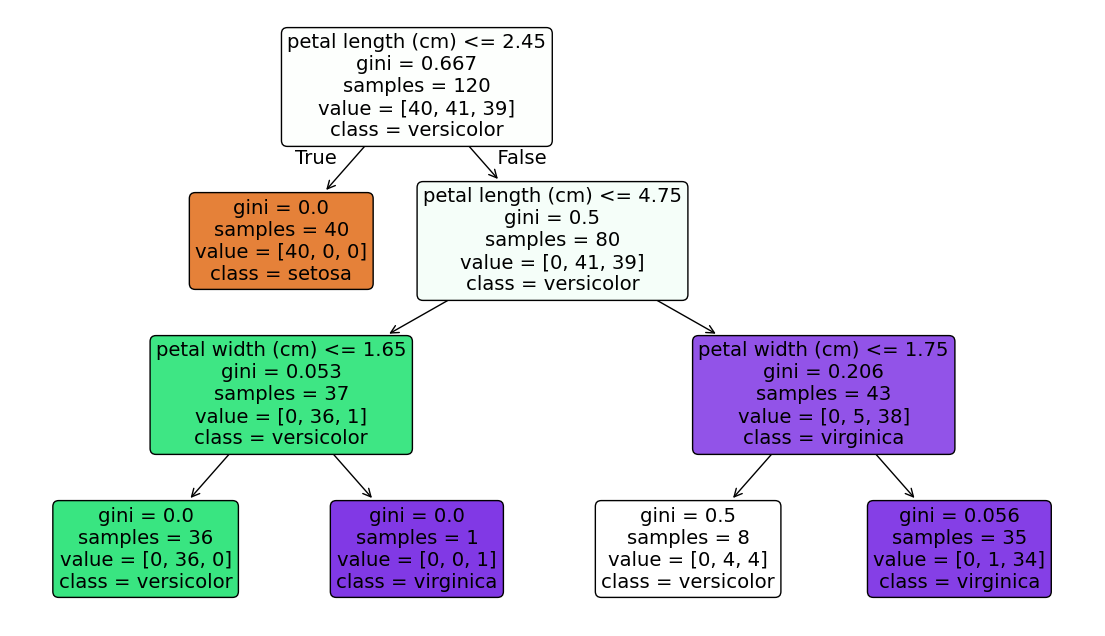

In [15]:
# Task 4
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(14, 8))
plot_tree(
    tree_model,                          # your max_depth=3 tree
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True,
)
plt.show()

_Write your Task 5 reflection here._
Reflection: Out of the three models, I found that ___ did the best on this dataset, with a test accuracy of ___. But honestly, the three scores were really close to each other. Since my test set only has 30 flowers, one wrong prediction changes the accuracy by about 3%, so I can’t say for sure that one model is actually better than the others. I think they all did so well because the Iris species are very easy to tell apart, especially using petal length and petal width, so even simple models can separate them without much trouble. Next time I’d use cross-validation to get a fairer comparison.